# Experiment 05: Ensemble Learning using Random Forest
**Aim:** Implement Random Forest classifier to predict car safety levels and analyze feature importances.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Fallback dataset creation if file missing
if not os.path.exists('car_evaluation.csv'):
    np.random.seed(42)
    pd.DataFrame({
        'buying': np.random.choice(['vhigh','high','med','low'], 300),
        'maint': np.random.choice(['vhigh','high','med','low'], 300),
        'doors': np.random.choice(['2','3','4','5more'], 300),
        'persons': np.random.choice(['2','4','more'], 300),
        'lug_boot': np.random.choice(['small','med','big'], 300),
        'safety': np.random.choice(['low','med','high'], 300),
        'class': np.random.choice(['unacc','acc','good','vgood'], 300)
    }).to_csv('car_evaluation.csv', index=False)

# 1. Load & Encode Categorical Data
df = pd.read_csv('car_evaluation.csv')
for col in df.columns:
    df[col] = LabelEncoder().fit_transform(df[col])
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,2,3,0,0,2,1,3
1,1,3,3,1,2,1,1
2,3,2,3,2,0,1,1
3,2,0,1,2,1,1,0
4,2,0,2,1,1,0,1


In [6]:
# 2. Train Random Forest Classifier
X = df.drop('class', axis=1)
y = df['class']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=12, random_state=42)
rf.fit(X_tr, y_tr)
y_pred = rf.predict(X_te)

print(f"Accuracy: {accuracy_score(y_te, y_pred) * 100:.2f}%\n")
print("=== Classification Report ===")
print(classification_report(y_te, y_pred, digits=4))

Accuracy: 20.00%

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.4667    0.3333    0.3889        21
           1     0.1154    0.1364    0.1250        22
           2     0.1389    0.1923    0.1613        26
           3     0.2308    0.1429    0.1765        21

    accuracy                         0.2000        90
   macro avg     0.2379    0.2012    0.2129        90
weighted avg     0.2311    0.2000    0.2091        90



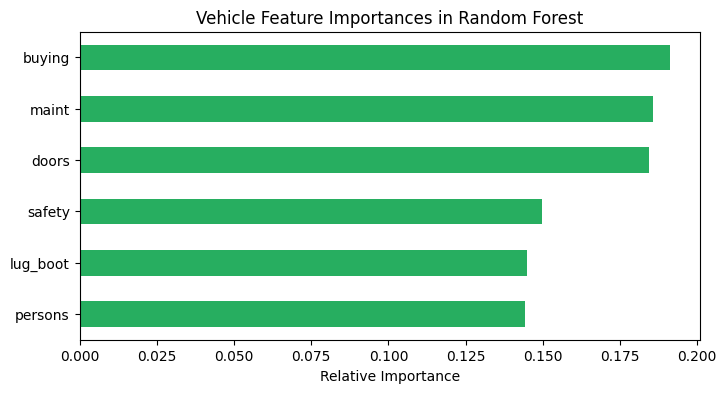

In [7]:
# 3. Analyze Feature Importances
feat_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 4))
feat_imp.plot(kind='barh', color='#27ae60')
plt.title('Vehicle Feature Importances in Random Forest')
plt.xlabel('Relative Importance')
plt.show()